# One Way ANOVA in Titanic Dataset

- In Titanic's dataset, there is a column named `Pclass (Categorical column)` where values are 1, 2 or 3
- We'll seperate these three classes and take 30% samples from each.
- Then with the help of these samples, we will prove if <br>
`Pop Mean Age for Pclass_1 = Pop Mean Age of Pclass_2 = Pop Mean Age of Pclass_3`

**Null Hypothesis:** mu Age P1 = mu Age P2 = Mu Age P3 <br>
**Alternate Hypothesis:** Mean of all or any one class is different

In [57]:
import pandas as pd
pd.set_option('display.float_format', '{:.25f}'.format)

In [58]:
df = pd.read_csv(r'00_Titanic_Dataset.csv')
df.dropna(inplace = True)

In [59]:
sampled_df = df.sample(frac=0.3)

In [60]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [61]:
model = ols('Age ~ C(Pclass)', data = sampled_df).fit()
model

In [62]:
anova_result = sm.stats.anova_lm(model, typ = 2)
anova_result

# Column PR(>F) is a P_Value

,sum_sq,df,F,PR(>F)
C(Pclass),1855.9222222222178970696404576,2.0000000000000000000000000,3.7306635695620036230479855,0.0283578844072358213224128
Residual,19401.6333333333350310567766428,78.0000000000000000000000000,NaN,NaN


In [63]:
p_value = anova_result.iloc[0,3]

if p_value < 0.05:
    print("""We reject the Null Hypothesis.
Means, population mean of all the groups or any one group is different.
""")
else:
    print("We failed to reject the Null Hypothesis")

We reject the Null Hypothesis.
Means, population mean of all the groups or any one group is different.



In [64]:
pclass_1 = df[(df['Pclass']==1)]
pclass_2 = df[(df['Pclass']==2)]
pclass_3 = df[(df['Pclass']==3)]


age_p1 = pclass_1['Age'].mean()
age_p2 = pclass_2['Age'].mean()
age_p3 = pclass_3['Age'].mean()

print(f'''**********Population Mean of Age Column**********

Pclass 1: {age_p1}
Pclass 2: {age_p2}
Pclass 3: {age_p3}
''')

# See, population mean of all classes are different.
# So, the conclusion we made using sample data, is correct.

**********Population Mean of Age Column**********

Pclass 1: 38.84923728813559
Pclass 2: 24.452380952380953
Pclass 3: 20.076923076923077



In [65]:
age_p1 = pclass_1['Age'].mean()
age_p2 = pclass_2['Age'].mean()
age_p3 = pclass_3['Age'].mean()

print(f'''**********Population Mean of Age Column**********

Pclass 1: {age_p1}
Pclass 2: {age_p2}
Pclass 3: {age_p3}
''')

# See, population mean of all classes are different.
# So, the conclusion we made using sample data, is correct.

**********Population Mean of Age Column**********

Pclass 1: 38.84923728813559
Pclass 2: 24.452380952380953
Pclass 3: 20.076923076923077



# 2) Post Hoc Test

In [66]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

turkey  = pairwise_tukeyhsd(
    endog = sampled_df['Age'],
    groups = sampled_df['Pclass'],
    alpha = 0.05
    )

pd.DataFrame(turkey.summary())

,0,1,2,3,4,5,6
0,group1,group2,meandiff,p-adj,lower,upper,reject
1,1,2,-16.4333,0.0432,-32.4627,-0.4039,True
2,1,3,-10.1,0.3545,-27.5434,7.3434,False
3,2,3,6.3333,0.7855,-16.4843,29.151,False


In [67]:
pd.DataFrame(
    turkey.summary().data[1:],
    columns = turkey.summary().data[0]
    )

    # See, mean difference from Pclass_1 to Pclass_2 is -16.80
    # from Pclass_1 to Pclass_3 is -18.08
    # from Pclass_2 to Pclass_3 is -1.28

    # This means Pclass_2 and Pclasss_3 are near but Pclass_1 is far from both 2 and 3.
    # So Pclass_3 is the culprit here.

,group1,group2,meandiff,p-adj,lower,upper,reject
0,1,2,-16.4332999999999991302956914,0.0432000000000000022870594,-32.4626999999999981127984938,-0.4038999999999999812594353,True
1,1,3,-10.0999999999999996447286321,0.3544999999999999817923424,-27.5433999999999983288034855,7.3433999999999999275246410,False
2,2,3,6.3333000000000003737454790,0.7854999999999999760191827,-16.4843000000000010629719327,29.1509999999999998010480340,False


In [68]:
turkey.summary().data

[['group1', 'group2', 'meandiff', 'p-adj', 'lower', 'upper', 'reject'],
 [1, 2, -16.4333, 0.0432, -32.4627, -0.4039, True],
 [1, 3, -10.1, 0.3545, -27.5434, 7.3434, False],
 [2, 3, 6.3333, 0.7855, -16.4843, 29.151, False]]

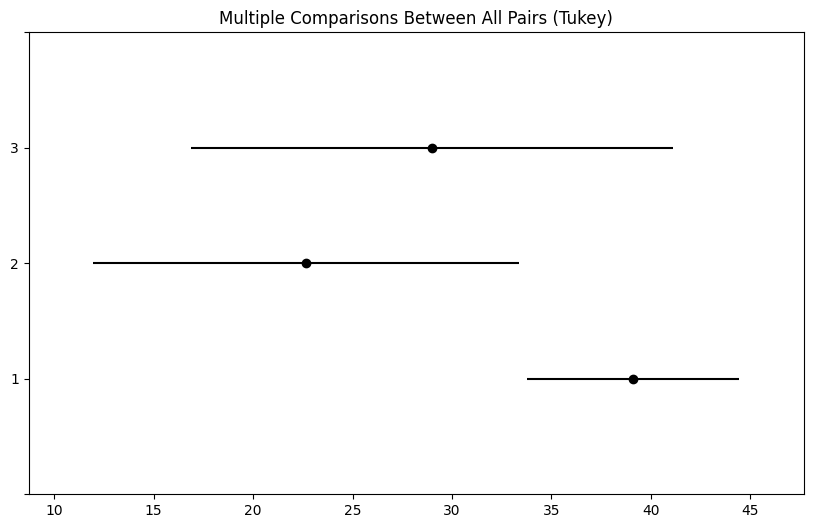

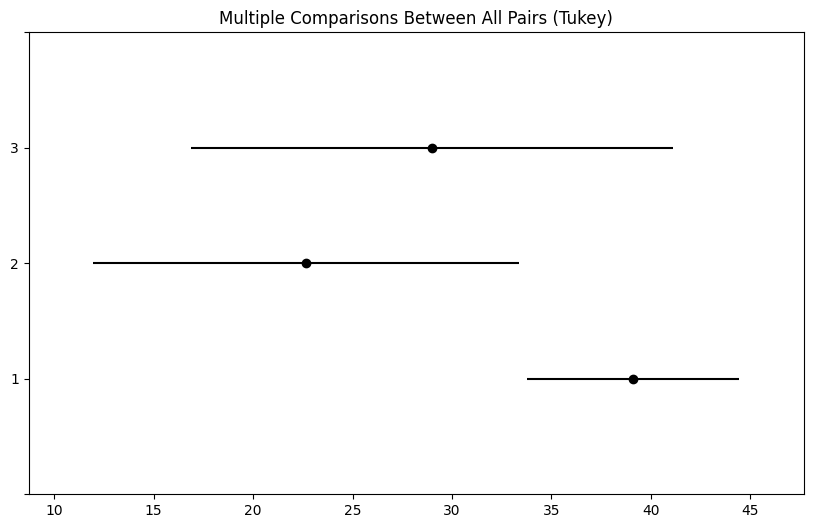

In [69]:
turkey.plot_simultaneous()

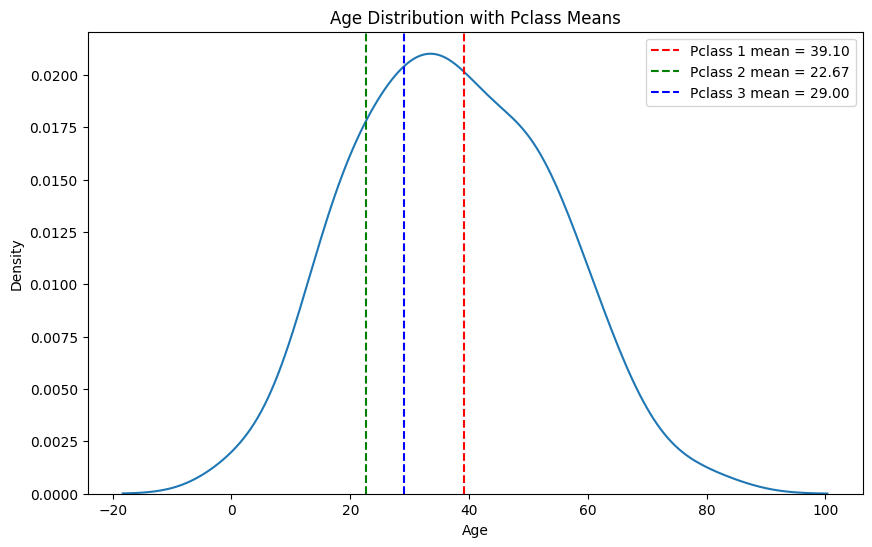

In [70]:
fig, ax = plt.subplots(figsize=(10, 6))

# KDE
sns.kdeplot(
    sampled_df['Age'],
    ax=ax
)

# Means of each Pclass
means = sampled_df.groupby('Pclass')['Age'].mean()

colors = {1: 'red', 2: 'green', 3: 'blue'}

# Add mean lines
for pclass, mean in means.items():
    ax.axvline(
        mean,
        linestyle='--',
        label=f'Pclass {pclass} mean = {mean:.2f}',
        color = colors[pclass]
    )

ax.set_title('Age Distribution with Pclass Means')
ax.set_xlabel('Age')
ax.set_ylabel('Density')
ax.legend()

plt.show()